In [1]:
import os
import re
import glob
from collections import Counter
import pandas as pd
from Bio import SeqIO
from datetime import datetime

# ── Configuration ────────────────────────────────────────────────────────
BASE_DIR = 'h3n2_clean'           # Master folder containing the season folders
FASTA_FILE = 'h3n2_clean.fasta'    # Master FASTA file with ground truth
OUTPUT_DIR = 'season_collected_fastas_unique'# Directory where the per-season FASTAs will be saved
HA1_LENGTH = 328                      # Length of HA1 segment (slice length)

# Create output directory if it doesn't exist
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [7]:
# ── Helpers ────────────────────────────────────────────────────────────

def load_fasta(fasta_path):
    print(f"Loading Master FASTA: {fasta_path}...")
    all_parsed_data = []
    
    if not os.path.exists(fasta_path):
        print(f"[ERROR] FASTA file not found at: {fasta_path}")
        return pd.DataFrame(columns=['id', 'date', 'zone', 'sequence'])
    
    for record in SeqIO.parse(fasta_path, "fasta"):
        # Use description to capture the full header line safely
        fields = record.description.split('|')
        if len(fields) < 6:
            continue
            
        date_str = fields[3].strip()
        try:
            date = datetime.strptime(date_str, '%Y-%m-%d')
            zone = fields[-1].strip()  # Extract zone from the end of the header
            sequence = str(record.seq).replace('-', '').replace('*', '')
            
            all_parsed_data.append({
                'id': record.description,
                'date': date, 
                'zone': zone,          
                'sequence': sequence
            })
        except ValueError:
            continue
            
    df = pd.DataFrame(all_parsed_data)
    print(f"✅ Loaded {len(df)} valid sequences with zones.")
    
    # GUARANTEE it never returns None, even if empty
    if df.empty:
        print("[WARNING] DataFrame is empty! Check if your header format matches `>ID|...|date|...|zone` (expects at least 6 pipe-separated fields).")
        
    return df

def get_consensus(seq_list, seq_max_len):
    consensus = []
    for pos in range(seq_max_len):
        aas = [s[pos] for s in seq_list if pos < len(s) and s[pos] not in ['-', 'X', '<PAD>']]
        if aas:
            top_aa = Counter(aas).most_common(1)[0][0]
            consensus.append(str(top_aa).strip().upper())
        else:
            consensus.append('-')
    return "".join(consensus)

def parse_predicted_fasta(filepath):
    try:
        with open(filepath, 'r') as f:
            lines = [line.strip() for line in f if not line.startswith('>')]
        return "".join(lines)
    except Exception:
        return None

In [8]:
# ── Main Extraction ────────────────────────────────────────────────────────
if not os.path.exists(BASE_DIR):
    print(f"[ERROR] Directory '{BASE_DIR}' does not exist!")
else:
    master_df = load_fasta(FASTA_FILE)
    
    # Ensure zone column fallback if missing
    if 'zone' not in master_df.columns:
        master_df['zone'] = 'Global'
        
    seq_max_len = int(master_df['sequence'].str.len().max())
    
    folder_pattern = re.compile(r"(\d{4})_season")
    season_folders = sorted([f for f in os.listdir(BASE_DIR) if os.path.isdir(os.path.join(BASE_DIR, f))])

    for sf in season_folders:
        match = folder_pattern.search(sf)
        if not match: continue
            
        target_year = int(match.group(1))
        season_dir = os.path.join(BASE_DIR, sf)
        
        out_fasta_path = os.path.join(OUTPUT_DIR, f"HA1_collected_{sf}.fasta")
        collected_count = 0
        
        with open(out_fasta_path, 'w') as out_f:
            print(f"\nProcessing Season Folder: {sf}")
            
            # 1. Calculate Test Consensus using UNIQUE sequences per zone
            test_start = pd.to_datetime(f"{target_year}-07-01")
            test_end   = pd.to_datetime(f"{target_year + 1}-01-31")
            test_df = master_df[(master_df['date'] >= test_start) & (master_df['date'] <= test_end)]
            
            if test_df.empty:
                print(f"  [!] No test data for {target_year}. Skipping consensus.")
            else:
                # --- COMBINED PER-ZONE UNIQUE FILTER ---
                test_df_unique = test_df.drop_duplicates(subset=['sequence', 'zone'])
                test_seqs_unique = test_df_unique['sequence'].tolist()
                
                print(f"  [i] Computing Unique Per-Zone Consensus from {len(test_seqs_unique)} sequences (out of {len(test_df)} total)...")
                
                test_consensus = get_consensus(test_seqs_unique, seq_max_len)
                
                # Slice to HA1 length
                test_consensus_ha1 = test_consensus[:HA1_LENGTH]
                
                # Write Unique Consensus to output
                header = f">{sf}|Test_Consensus_Unique_Per_Zone|Length_{len(test_consensus_ha1)}\n"
                out_f.write(header)
                out_f.write(f"{test_consensus_ha1}\n")
            
            # 2. Collect ALL Model Predictions from subfolders
            fasta_files = glob.glob(os.path.join(season_dir, "**", "*.fasta"), recursive=True)
            
            if not fasta_files:
                print("  [-] No prediction fasta files found in subfolders.")
                continue
                
            for fasta_path in fasta_files:
                file_name = os.path.basename(fasta_path)
                
                rel_path = os.path.relpath(fasta_path, season_dir)
                subfolder_name = os.path.dirname(rel_path)
                if not subfolder_name: 
                    subfolder_name = "root_dir"
                
                pred_seq = parse_predicted_fasta(fasta_path)
                
                if pred_seq:
                    pred_seq_ha1 = pred_seq[:HA1_LENGTH]
                    
                    header = f">{sf}|{subfolder_name}|{file_name}|Length_{len(pred_seq_ha1)}\n"
                    out_f.write(header)
                    out_f.write(f"{pred_seq_ha1}\n")
                    collected_count += 1
                    
        print(f"  ✅ Saved {collected_count} prediction sequences + unique consensus to: {out_fasta_path}")

    print("\n" + "="*80)
    print(f"🎉 All seasons processed! Check the '{OUTPUT_DIR}' folder.")
    print("="*80)

Loading Master FASTA: h3n2_clean.fasta...
✅ Loaded 193102 valid sequences with zones.

Processing Season Folder: 2014_season_(train_2011_2014)
  [i] Computing Unique Per-Zone Consensus from 1581 sequences (out of 5205 total)...
  ✅ Saved 9 prediction sequences + unique consensus to: season_collected_fastas_unique/HA1_collected_2014_season_(train_2011_2014).fasta

Processing Season Folder: 2015_season_(train_2012_2015)
  [i] Computing Unique Per-Zone Consensus from 1218 sequences (out of 3321 total)...
  ✅ Saved 9 prediction sequences + unique consensus to: season_collected_fastas_unique/HA1_collected_2015_season_(train_2012_2015).fasta

Processing Season Folder: 2016_season_(train_2013_2016)
  [i] Computing Unique Per-Zone Consensus from 2875 sequences (out of 8958 total)...
  ✅ Saved 9 prediction sequences + unique consensus to: season_collected_fastas_unique/HA1_collected_2016_season_(train_2013_2016).fasta

Processing Season Folder: 2017_season_(train_2014_2017)
  [i] Computing Uniq

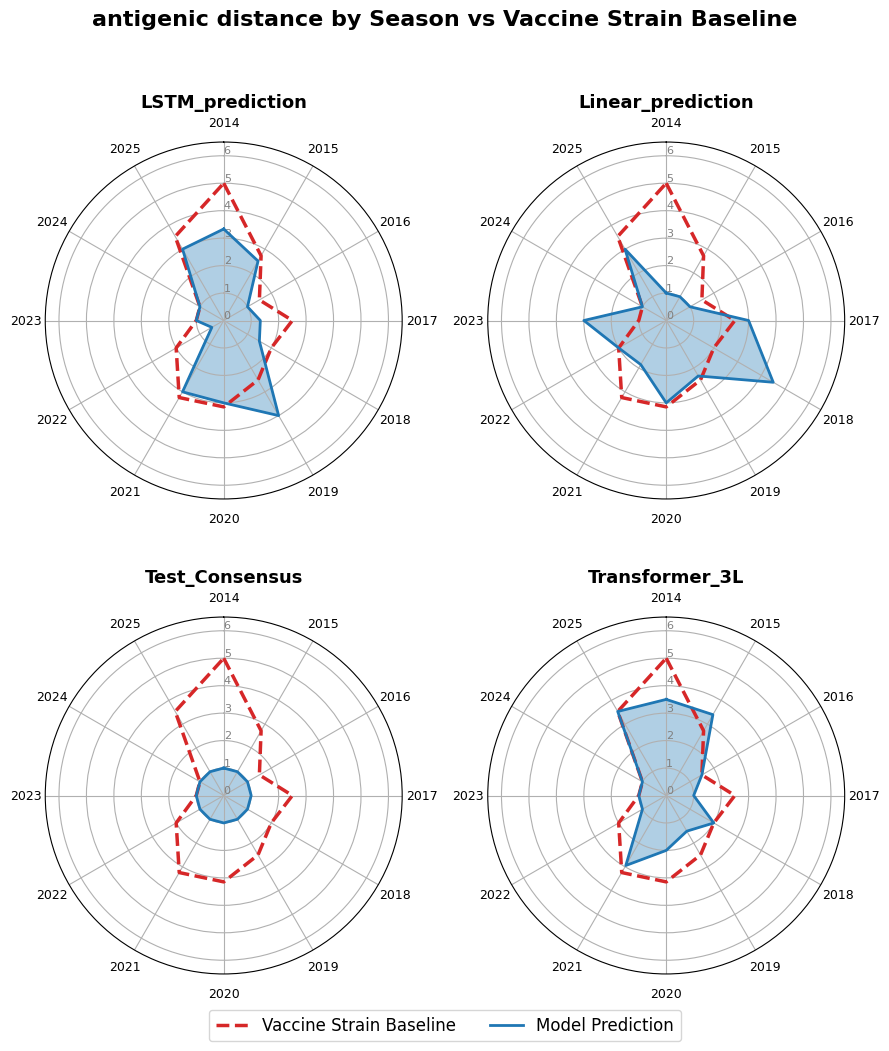

In [19]:
import pandas as pd
import glob
import re
import math
import matplotlib.pyplot as plt

# ==========================================
# 1. LOAD AND COMBINE CSV FILES
# ==========================================
csv_files = glob.glob("antigenic_distance_U/HI_results_U_20*.csv")
df_list = []

for file in csv_files:
    match = re.search(r'HI_results_U_(\d{4})', file)
    if not match: continue
        
    season = int(match.group(1))
    temp_df = pd.read_csv(file)
    temp_df = temp_df[temp_df['virus1'].astype(str).str.contains('Test_Consensus', na=False, case=False)]
    temp_df['Season'] = season
    df_list.append(temp_df)

# FIX 4: Protect against empty list
if not df_list:
    raise ValueError("No matching data found. Check your file path and filter criteria.")

df = pd.concat(df_list, ignore_index=True)

# ==========================================
# 2. CLEAN UP MODEL NAMES
# ==========================================
def fix_model_names(name):
    name_str = str(name).lower()
    
    # 1. Check Baselines and Ensembles first
    if 'vaccine' in name_str: return 'Vaccine Strain'
    if 'hotspot' in name_str: return 'Ensemble_all'
    if 'ensemble_entropy' in name_str: return 'Ensemble_Entropy'
    if 'ensemble_majority' in name_str: return 'Ensemble_MajorityVote'
    if 'test_consensus' in name_str: return 'Test_Consensus'
    
    # 2. Check individual AI models
    if 'lstm' in name_str: return 'LSTM_prediction'
    if 'linear' in name_str: return 'Linear_prediction'
    if 'transformer_3l' in name_str: return 'Transformer_3L'
    if 'transformer_4l' in name_str: return 'Transformer_4L'
    if 'transformer_5l' in name_str: return 'Transformer_5L'
    
    # 3. FIX: Be specific about 'train_consensus' so 'train_2011' doesn't trigger it
    if 'train_consensus' in name_str: return 'Train_consensus'
    
    return name

df['Model'] = df['virus2'].apply(fix_model_names)
df = df[~df['Model'].str.startswith('Ensemble')]
#df = df[~df['Model'].str.startswith('Test_')]
df = df[~df['Model'].isin(['Transformer_4L', 'Transformer_5L'])].copy()


# ==========================================
# 3. PREPARE DATA FOR RADAR CHART
# ==========================================
metric_to_plot = 'antigenic_distance'  

df_radar = df.pivot_table(index='Model', columns='Season', values=metric_to_plot, aggfunc='mean')
seasons = sorted(df_radar.columns.tolist())
df_radar = df_radar[seasons]

categories = [str(s) for s in seasons]
N = len(categories)
angles = [n / float(N) * 2 * math.pi for n in range(N)]
angles += angles[:1] 

if 'Vaccine Strain' in df_radar.index:
    models = [m for m in df_radar.index if m != 'Vaccine Strain']
    baseline_values = df_radar.loc['Vaccine Strain'].values.tolist()
    baseline_values += baseline_values[:1] 
else:
    models = list(df_radar.index)
    baseline_values = [0] * (N + 1) 
    
num_models = len(models)

# FIX 3: Protect against 0 models
if num_models == 0:
    print("No models left to plot after filtering!")
else:
    cols = 2
    rows = math.ceil(num_models / cols)

    # ==========================================
    # 4. PLOTTING THE SMALL MULTIPLES
    # ==========================================
    fig, axes = plt.subplots(rows, cols, figsize=(9, 5 * rows), subplot_kw=dict(polar=True))

    # FIX 1: Safely flatten axes (Works safely for all combinations where cols=3)
    axes = axes.flatten() if isinstance(axes, (list, tuple, __import__('numpy').ndarray)) else [axes]

    ymin = 0
    ymax = 6.5

    for i, model in enumerate(models):
        ax = axes[i]
        
        model_values = df_radar.loc[model].values.tolist()
        model_values += model_values[:1]
        
        ax.plot(angles, baseline_values, linewidth=2.5, linestyle='--', color='tab:red', label='Vaccine Strain Baseline')
        ax.plot(angles, model_values, linewidth=2, linestyle='solid', color='tab:blue', label='Model Prediction')
        ax.fill(angles, model_values, color='tab:blue', alpha=0.35)
        
        ax.set_xticks(angles[:-1])
        ax.set_xticklabels(categories, size=9)
        ax.set_theta_offset(math.pi / 2) 
        ax.set_theta_direction(-1)       
        
        ax.set_rorigin(ymin) 
        ax.set_ylim(ymin, ymax) 
        ax.set_rlabel_position(0) 
        ax.set_yticks([0, 1, 2, 3, 4, 5,6]) 
        ax.set_yticklabels(["0", "1", "2", "3", "4", "5","6"], color="grey", size=8)
        
        ax.set_title(model, size=13, weight='bold', position=(0.5, 1.1))

    # FIX 2: Safely clean up empty subplots without relying on 'i'
    for j in range(len(models), len(axes)):
        fig.delaxes(axes[j])

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.02), ncol=2, fontsize=12)

    plt.suptitle(f'{metric_to_plot.replace("_", " ")} by Season vs Vaccine Strain Baseline', size=16, weight='bold', y=1.02)
    plt.tight_layout()

    plt.savefig(f"spider_U_{metric_to_plot}_zoomed.png", dpi=300, bbox_inches='tight')
    plt.show()